In [ ]:
# 2024/08/05
# Ziming Xu, Univeristy of Alberta
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
import time

## Ground Truth Function Construction
* The data is generated, the training/testing data are split
* The testing data is unknown for the models

In [4]:
# orginal function
def func1(x,d,e):
    y = d*(np.cos(x+e)+np.sin(x+e))
    return y

# estimator
def func2(x,a,b,c):
    y = a*np.cos(b*x+c)
    return y

(200, 100) (200, 2)
(5000, 100) (5000, 3)


Text(0, 0.5, '$Y$ or $\\hat{Y}$')

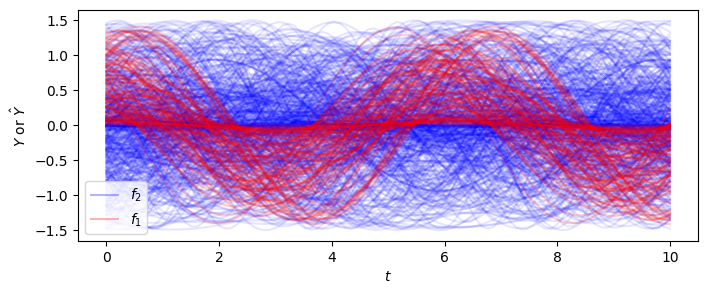

In [5]:
# target data
org_data = []
org_features = []
np.random.seed(66)
x = np.linspace(0,10,100)
for i in range(200):
  d = np.random.uniform(0,1)
  e = np.random.uniform(0,2)
  org = func1(x,d,e)
  org_data.append(org)
  org_features.append([d,e])

org_data = np.array(org_data)
org_features = np.array(org_features)

print(org_data.shape, org_features.shape)

# simulation data
sim_data = []
sim_features = []
for i in range(5000):
  a = np.random.uniform(0,1.5)
  b = np.random.uniform(0,2)
  c = np.random.uniform(-np.pi,np.pi)
  sim = func2(x,a,b,c)
  sim_data.append(sim)
  sim_features.append([a,b,c])

sim_data = np.array(sim_data)
sim_features = np.array(sim_features)

print(sim_data.shape, sim_features.shape)


# Plot simulated data with one label
plt.figure(figsize=(8, 3))
t = np.linspace(0,10,100)
for i in range(500):
    if i == 0:
        plt.plot(t, sim_data[i], color='b', alpha=0.3, label='$f_2$')
    else:
        plt.plot(t, sim_data[i], color='b', alpha=0.1)

# Plot original data with one label
for i in range(100):
    if i == 0:
        plt.plot(t, org_data[i], color='r', alpha=0.3, label='$f_1$')
    else:
        plt.plot(t, org_data[i], color='r', alpha=0.2)

plt.legend()
plt.xlabel('$t$')
plt.ylabel(r'$Y$ or $\hat{Y}$')  # Use raw string + LaTeX


## Build and train Component 1: Proxy

In [6]:
sim_data_reshape = sim_data.reshape(-1, 100, 1)
sim_data_train = sim_data_reshape[:4900]
sim_features_train = sim_features[:4900]

sim_data_test = sim_data_reshape[4900:]
sim_features_test = sim_features[4900:]

print(sim_data_train.shape, sim_features_train.shape)
print(sim_data_test.shape, sim_features_test.shape)

(4900, 100, 1) (4900, 3)
(100, 100, 1) (100, 3)


In [ ]:
import tensorflow as tf
from tensorflow import keras
def attention_block(inputs):
    attention = keras.layers.Dense(1, activation='tanh')(inputs)
    attention = keras.layers.Flatten()(attention)
    attention = keras.layers.Activation('softmax')(attention)
    attention = keras.layers.RepeatVector(128)(attention)
    attention = keras.layers.Permute([2, 1])(attention)
    return keras.layers.Multiply()([inputs, attention])

def attention_block(inputs):
    """
    Corrected attention mechanism for single-feature sequences.
    Inputs: Tensor of shape (batch_size, timesteps, 1)
    Outputs: Attention-weighted tensor of same shape
    """
    attention = keras.layers.Dense(1, activation='tanh')(inputs)  # (batch, timesteps, 1)
    attention = keras.layers.Flatten()(attention)  # (batch, timesteps)
    attention = keras.layers.Softmax(axis=1)(attention)  # Apply across timesteps
    attention = keras.layers.RepeatVector(1)(attention)  # (batch, 1, timesteps)
    attention = keras.layers.Permute([2, 1])(attention)  # (batch, timesteps, 1)

    return keras.layers.Multiply()([inputs, attention])  # Apply attention weights

In [ ]:
# build a GRU model for regression task

inputs = keras.layers.Input(shape=(sim_features_train.shape[1],))
x = keras.layers.RepeatVector(100)(inputs)
x = keras.layers.GRU(128, return_sequences=True)(x)
x = keras.layers.Dropout(0.2)(x)
x = attention_block(x)
x = keras.layers.GRU(128, return_sequences=True)(x)
x = keras.layers.Dropout(0.2)(x)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dense(1, activation='linear')(x)

model = keras.models.Model(inputs=inputs, outputs=x)
optimizer = keras.optimizers.Adam(learning_rate=0.001)
model.compile(loss='mse', optimizer=optimizer)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 100, 3)    │          0 │ input_layer[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 100, 128)  │     51,072 │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 100, 128)  │          0 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 100, 1)    │        129 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 100)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Softmax)   │ (None, 100)       │          0 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_1     │ (None, 1, 100)    │          0 │ softmax[0][0]     │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 100, 1)    │          0 │ repeat_vector_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 100, 128)  │          0 │ dropout[0][0],    │
│                     │                   │            │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 100, 128)  │     99,072 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 100, 128)  │          0 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 100, 128)  │     16,512 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 100, 1)    │        129 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 166,914 (652.01 KB)

 Trainable params: 166,914 (652.01 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: loss = {logs['loss']:.5f}, val_loss = {logs.get('val_loss', 0):.5f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: loss = {logs['loss']:.5f}, val_loss = {logs.get('val_loss', 0):.5f}")

# Automatically save the model with the lowest val_loss
checkpoint_cb = ModelCheckpoint(
    filepath= "your path",
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    verbose=0  # set to 1 to print a message when saving
)

proxy_history = model.fit(sim_features_train, sim_data_train, epochs=3000, batch_size=512, validation_split=0.1, verbose = 0, callbacks=[EveryNVerbose(n=50), checkpoint_cb])

plt.plot(proxy_history.history['loss'], label='train')
plt.plot(proxy_history.history['loss'], label='validate')
plt.legend()
plt.yscale('log')

Epoch 1: loss = 0.36826, val_loss = 0.35874
Epoch 50: loss = 0.07809, val_loss = 0.07422
Epoch 100: loss = 0.02919, val_loss = 0.02363
Epoch 150: loss = 0.02153, val_loss = 0.01326
Epoch 200: loss = 0.01569, val_loss = 0.00963
Epoch 250: loss = 0.01305, val_loss = 0.00871
Epoch 300: loss = 0.01826, val_loss = 0.01671
Epoch 350: loss = 0.01312, val_loss = 0.00740
Epoch 400: loss = 0.01566, val_loss = 0.01108
Epoch 450: loss = 0.00888, val_loss = 0.00527
Epoch 500: loss = 0.00696, val_loss = 0.00345
Epoch 550: loss = 0.00690, val_loss = 0.00465
Epoch 600: loss = 0.00831, val_loss = 0.00323
Epoch 650: loss = 0.00511, val_loss = 0.00194
Epoch 700: loss = 0.00612, val_loss = 0.00385
Epoch 750: loss = 0.00627, val_loss = 0.00642
Epoch 800: loss = 0.00450, val_loss = 0.00121
Epoch 850: loss = 0.00423, val_loss = 0.00263
Epoch 900: loss = 0.00964, val_loss = 0.00910
Epoch 950: loss = 0.00360, val_loss = 0.00100
Epoch 1000: loss = 0.00354, val_loss = 0.00128
Epoch 1050: loss = 0.00326, val_loss

In [ ]:
proxy = tf.keras.models.load_model('your path')
y_pred = proxy.predict(sim_features_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 155ms/step


Text(0, 0.5, '$Y$')

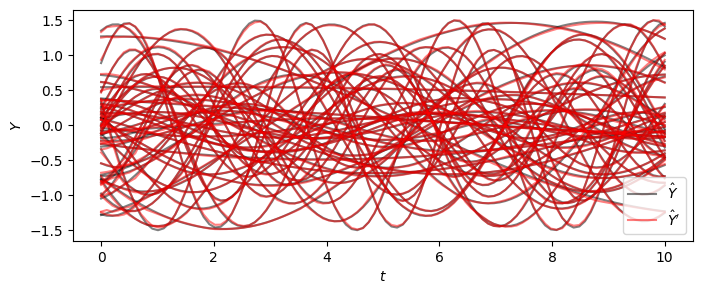

In [ ]:
# Plot simulated data with one label
plt.figure(figsize=(8, 3))
t = np.linspace(0,10,100)
for i in range(50):
    if i == 0:
        plt.plot(t, sim_data_test[i], color = 'k', alpha = 0.5, label = '$\hat{Y}$')
    else:
        plt.plot(t, sim_data_test[i], color = 'k', alpha = 0.5)

# Plot original data with one label
for i in range(50):
    if i == 0:
        plt.plot(t, y_pred[i], color = 'r', alpha = 0.5, label = r'$\hat{Y}^\prime$')
    else:
       plt.plot(t, y_pred[i], color = 'r', alpha = 0.5)

plt.legend()
plt.xlabel('$t$')
plt.ylabel(r'$Y$')  # Use raw string + LaTeX

## Build and Train Component 2: VAE

In [8]:
class Sampling(keras.layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [ ]:
latent_dim = 32

# VAE_Encoder
encoder_input = keras.layers.Input(shape=(sim_features_train.shape[1],))

VAE_en1 = keras.layers.Dense(64, activation = 'relu')(encoder_input)
VAE_en1 = keras.layers.Dropout(0.2)(VAE_en1)
VAE_en2 = keras.layers.Dense(64, activation = 'relu')(VAE_en1)
VAE_en2 = keras.layers.Dropout(0.2)(VAE_en2)

x = keras.layers.Flatten()(VAE_en2)
z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

# Define the model
VAE_encoder = keras.Model([encoder_input], [z_mean, z_log_var, z], name="VAE_encoder")
VAE_encoder.summary()

Model: "VAE_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      4,160 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 64)        │          0 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      2,080 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      2,080 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,576 (33.50 KB)

 Trainable params: 8,576 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# VAE_Decoder
decoder_input = keras.Input(shape=(latent_dim,),name='latent_input')

VAE_de1 = keras.layers.Dense(64, activation = 'relu')(decoder_input)
VAE_de1 = keras.layers.Dropout(0.2)(VAE_de1)
VAE_de2 = keras.layers.Dense(64, activation = 'relu')(VAE_de1)
VAE_de2 = keras.layers.Dropout(0.2)(VAE_de2)
VAE_de_dense1 = keras.layers.Dense(64, activation='tanh')(VAE_de2)
VAE_de_output = keras.layers.Dense(sim_features_train.shape[1], activation = 'linear')(VAE_de_dense1)

VAE_decoder = keras.Model([decoder_input], VAE_de_output, name="VAE_decoder")
VAE_decoder.summary()

Model: "VAE_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latent_input (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,627 (41.51 KB)

 Trainable params: 10,627 (41.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#%% Define VAE
class Build_VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.gamma = 5000 # add weight to the reonstruction loss
        self.encoder = VAE_encoder
        self.decoder = VAE_decoder
        self.encoder_loss_tracker = keras.metrics.Mean(name="encoder_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")

        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)

    @property
    def metrics(self):
        return [
            self.encoder_loss_tracker,
            self.recons_loss_tracker]

    def train_step(self, data):
        en_features = data[0][0]

        # VAE
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder([en_features])

            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))

            reconstruction = self.decoder([z])
            reconstruction_loss = tf.reduce_mean(tf.keras.losses.MeanSquaredError()(en_features, reconstruction))
            encoder_loss = kl_loss+reconstruction_loss*self.gamma

        grads = tape.gradient(encoder_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.encoder_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(reconstruction_loss)

        return {
            "kl": self.encoder_loss_tracker.result(),
            "recons": self.recons_loss_tracker.result()}

In [ ]:
vae = Build_VAE(VAE_encoder, VAE_decoder)
vae.compile(tf.keras.optimizers.Adam())

In [ ]:
from tensorflow.keras.callbacks import Callback, ModelCheckpoint
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: kl = {logs['kl']:.5f}, reconstruction = {logs.get('recons', 0):.8f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: kl = {logs['kl']:.5f}, reconstruction = {logs.get('recons', 0):.8f}")

# Automatically save the encoder and the decoder
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, decoder_path, monitor='recons', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.decoder_path = decoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            print(f"Saving encoder and decoder at epoch {epoch + 1} with {self.monitor}: {current:.6f}")
            self.model.encoder.save(self.encoder_path)
            self.model.decoder.save(self.decoder_path)

save_cb = SaveEncoderDecoder(
    encoder_path='your path',
    decoder_path='your path',
    monitor='recons',
    save_best_only=True
)

vae_history = vae.fit([sim_features_train], epochs=2000, batch_size=512, verbose = 0, callbacks= [EveryNVerbose(n=50), save_cb])

Epoch 1: kl = 1.07558, reconstruction = 1.37417662
Saving encoder and decoder at epoch 1 with recons: 1.374177
Saving encoder and decoder at epoch 2 with recons: 0.873182
Saving encoder and decoder at epoch 3 with recons: 0.450674
Saving encoder and decoder at epoch 4 with recons: 0.327224
Saving encoder and decoder at epoch 5 with recons: 0.265382
Saving encoder and decoder at epoch 6 with recons: 0.219491
Saving encoder and decoder at epoch 7 with recons: 0.182578
Saving encoder and decoder at epoch 8 with recons: 0.151872
Saving encoder and decoder at epoch 9 with recons: 0.126749
Saving encoder and decoder at epoch 10 with recons: 0.106340
Saving encoder and decoder at epoch 11 with recons: 0.088767
Saving encoder and decoder at epoch 12 with recons: 0.070794
Saving encoder and decoder at epoch 13 with recons: 0.050955
Saving encoder and decoder at epoch 14 with recons: 0.030904
Saving encoder and decoder at epoch 15 with recons: 0.020858
Saving encoder and decoder at epoch 16 with

In [ ]:
vae.encoder.save('your path')
vae.decoder.save('your path')

In [ ]:
custom_objects = {'Sampling': Sampling}
vae_encoder_model = tf.keras.models.load_model('your path',custom_objects=custom_objects)
vae_decoder_model = tf.keras.models.load_model('your path')

In [10]:
en_pred = vae_encoder_model.predict([sim_features_test])
de_pred = vae_decoder_model.predict([en_pred[2]]) # 0 is z mean, 1 is variance, 2 is sampled z; if you train a deterministic model, then use z mean
print(sim_features_test[1,:])
print(de_pred[1,:])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step 


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_3
Received: inputs=('Tensor(shape=(32, 3))',)
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_3
Received: inputs=('Tensor(shape=(None, 3))',)
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: latent_input
Received: inputs=('Tensor(shape=(32, 32))',)
  warnings.warn(msg)


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step 
[ 1.34826302  1.37604105 -2.18259323]
[ 1.3444513  1.3820012 -2.1686985]


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: latent_input
Received: inputs=('Tensor(shape=(None, 32))',)
  warnings.warn(msg)


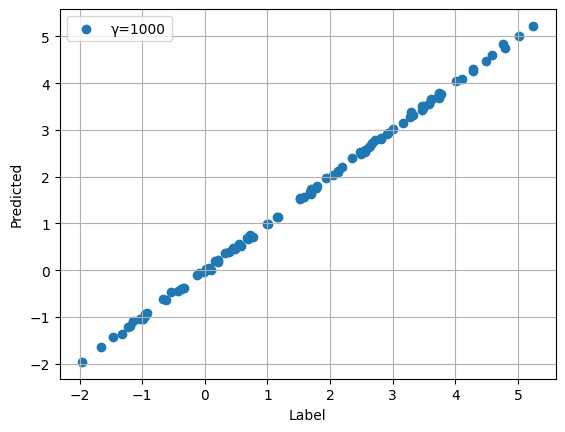

In [14]:
x_test_sum = np.sum(sim_features_test,axis=1)
de_pred_sum = np.sum(de_pred,axis=1)
plt.scatter(x_test_sum,de_pred_sum,label="γ=1000")
plt.xlabel('Label')
plt.ylabel('Predicted')
plt.grid()
plt.legend()

## Build and Train Component 3: AssimNet

In [ ]:
org_data_reshape = org_data.reshape(-1, 100, 1)
split_n = 100
org_data_train = org_data_reshape[:split_n]
org_features_train = org_features[:split_n]

org_data_test = org_data_reshape[split_n:]
org_features_test = org_features[split_n:]

print(org_data_train.shape, org_features_train.shape)
print(org_data_test.shape, org_features_test.shape)

(100, 100, 1) (100, 2)
(100, 100, 1) (100, 2)


In [ ]:
## Define the Encoder
encoder_input = keras.layers.Input(shape=(org_features_train.shape[1],))

Assim_en1 = keras.layers.Dense(128, activation = 'relu')(encoder_input)
Assim_en1 = keras.layers.Dropout(0.2)(Assim_en1)
Assim_en2 = keras.layers.Dense(128, activation = 'relu')(Assim_en1)
Assim_en2 = keras.layers.Dropout(0.2)(Assim_en2)

x = keras.layers.Flatten()(Assim_en2)
z_mean = keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = keras.layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

# Define the model
Assim_encoder = keras.Model([encoder_input], [z_mean, z_log_var, z], name="Assim_encoder")
Assim_encoder.summary()

Model: "Assim_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 128)       │        384 │ input_layer_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_20          │ (None, 128)       │          0 │ dense_25[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_26 (Dense)    │ (None, 128)       │     16,512 │ dropout_20[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 128)       │          0 │ dense_26[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 128)       │          0 │ dropout_21[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_6          │ (None, 32)        │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,152 (98.25 KB)

 Trainable params: 25,152 (98.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p):
    """KL divergence between two multivariate diagonal Gaussians"""
    var_q = tf.exp(logvar_q)
    var_p = tf.exp(logvar_p)

    kl = 0.5 * (
        tf.reduce_sum(logvar_p - logvar_q, axis=1)  # log |Σ_p| / |Σ_q|
        - tf.cast(tf.shape(mu_q)[1], tf.float32)    # -k
        + tf.reduce_sum(var_q / var_p, axis=1)       # Tr(Σ_p^-1 Σ_q)
        + tf.reduce_sum((mu_p - mu_q)**2 / var_p, axis=1)  # diff^T Σ_p^-1 diff
    )
    return tf.reduce_mean(kl)

class Build_AssimNet(keras.Model):
    def __init__(self, assim_encoder, vae_encoder, decoder, proxy, **kwargs):
        super().__init__(**kwargs)
        self.assim_encoder = assim_encoder
        self.vae_encoder = vae_encoder
        self.decoder = decoder
        self.proxy = proxy
        self.lam = 0.001
        self.assim_loss_tracker = keras.metrics.Mean(name="assim_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")
        self.recons_loss_tracker = keras.metrics.Mean(name="recons_loss")
        self.optimizer = tf.keras.optimizers.Adam(learning_rate = 0.0001)

        # Set decoder and proxy as untrainable
        self.vae_encoder.trainable = False
        self.decoder.trainable = False
        self.proxy.trainable = False

    @property
    def metrics(self):
        return [self.assim_loss_tracker,
                self.kl_loss_tracker,
                self.recons_loss_tracker]

    def train_step(self, data):
        en_features = data[0][0]
        assim_target = data[0][1]

        # VAE
        with tf.GradientTape() as tape:
            mu_q, logvar_q, z = self.assim_encoder([en_features])
            # Disgnostic
            recons4vae_encoder = self.decoder([z])
            mu_p, logvar_p, _ = self.vae_encoder([recons4vae_encoder])
            kl_loss = kl_divergence_between_gaussians(mu_q, logvar_q, mu_p, logvar_p)

            simu_in_recons = self.decoder([z])
            proxy_out = self.proxy(simu_in_recons)
            recons_loss = tf.keras.losses.MeanSquaredError()(proxy_out, assim_target)
            assim_loss = recons_loss + self.lam*kl_loss

        grads = tape.gradient(assim_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.assim_loss_tracker.update_state(assim_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        self.recons_loss_tracker.update_state(recons_loss)

        return {"assim_loss": self.assim_loss_tracker.result(),
                "kl_loss": self.kl_loss_tracker.result(),
                "recons": self.recons_loss_tracker.result()}

In [ ]:
AssimNet = Build_AssimNet(Assim_encoder, vae_encoder_model, vae_decoder_model, proxy)
AssimNet.compile(tf.keras.optimizers.Adam())

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: latent_input
Received: inputs=['Tensor(shape=(None, 32))']
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer_3
Received: inputs=['Tensor(shape=(None, 3))']
  warnings.warn(msg)


Epoch 1: assim_loss = 8.97077, kl_loss = 8372.13379, recons = 0.59863758
Saving assimnet encoder at epoch 1 with assim_loss: 8.970772
Saving assimnet encoder at epoch 2 with assim_loss: 8.379834
Saving assimnet encoder at epoch 3 with assim_loss: 7.612819
Saving assimnet encoder at epoch 4 with assim_loss: 7.600700
Saving assimnet encoder at epoch 5 with assim_loss: 7.131884
Saving assimnet encoder at epoch 7 with assim_loss: 6.485689
Epoch 10: assim_loss = 6.55099, kl_loss = 6012.87256, recons = 0.53812110
Saving assimnet encoder at epoch 11 with assim_loss: 5.798923
Saving assimnet encoder at epoch 12 with assim_loss: 5.241225
Saving assimnet encoder at epoch 13 with assim_loss: 5.041071
Saving assimnet encoder at epoch 14 with assim_loss: 4.792603
Saving assimnet encoder at epoch 15 with assim_loss: 4.416884
Saving assimnet encoder at epoch 17 with assim_loss: 4.163135
Saving assimnet encoder at epoch 18 with assim_loss: 3.799968
Saving assimnet encoder at epoch 19 with assim_loss: 

Text(0, 0.5, 'KL Loss')

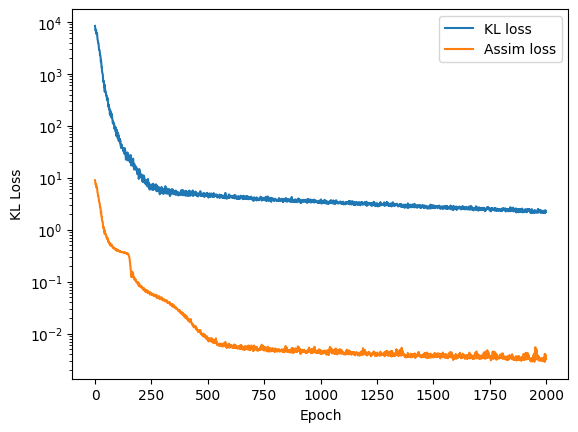

In [ ]:
class EveryNVerbose(Callback):
    def __init__(self, n=5):
        super().__init__()
        self.n = n

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0:
            print(f"Epoch {epoch + 1}: assim_loss = {logs['assim_loss']:.5f}, kl_loss = {logs.get('kl_loss', 0):.5f}, recons = {logs.get('recons', 0):.8f}")
        elif (epoch + 1) % self.n == 0:
            print(f"Epoch {epoch + 1}: assim_loss = {logs['assim_loss']:.5f}, kl_loss = {logs.get('kl_loss', 0):.5f}, recons = {logs.get('recons', 0):.8f}")

# Automatically save the model with the lowest val_loss
class SaveEncoderDecoder(Callback):
    def __init__(self, encoder_path, monitor='recon', save_best_only=True):
        super().__init__()
        self.encoder_path = encoder_path
        self.monitor = monitor
        self.save_best_only = save_best_only
        self.best = float('inf')  # initialize as very bad (infinite loss)

    def on_epoch_end(self, epoch, logs=None):
        current = logs.get(self.monitor)
        if current is None:
            print(f"Warning: Metric '{self.monitor}' not found in logs.")
            return

        # Save if either not save_best_only or new best
        if not self.save_best_only or current < self.best:
            self.best = current
            print(f"Saving assimnet encoder at epoch {epoch + 1} with {self.monitor}: {current:.6f}")
            self.model.assim_encoder.save(self.encoder_path)

save_cb = SaveEncoderDecoder(
    encoder_path='your path',
    monitor='assim_loss',
    save_best_only=True
)

assim_history = AssimNet.fit([org_features_train,org_data_train],epochs=2000, batch_size=512, verbose=0, callbacks=[EveryNVerbose(n=10), save_cb])

plt.plot(assim_history.history['kl_loss'], label='KL loss')
plt.plot(assim_history.history['assim_loss'], label='Assim loss')
plt.legend()
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('KL Loss')

In [ ]:
import pickle
history = pickle.load(open('your path', 'rb'))
custom_objects = {'Sampling': Sampling}
AssimNet_encoder = tf.keras.models.load_model('your path',custom_objects=custom_objects)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


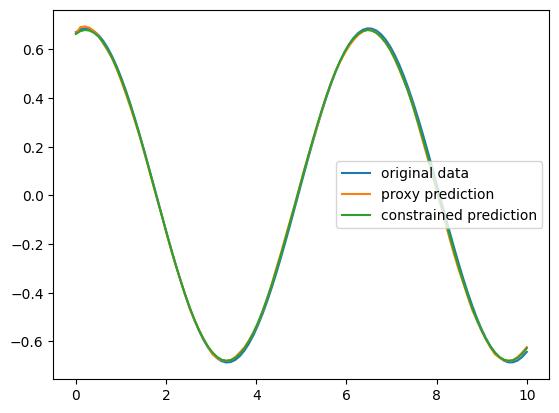

In [ ]:
latent_pred = AssimNet_encoder.predict([org_features_test])
simu_in_pred = vae_decoder_model.predict([latent_pred[0]])
y_pred = proxy.predict(simu_in_pred)

x = np.linspace(0,10,100)
plot_i = 0
constrained_out = func2(x,simu_in_pred[plot_i][0],simu_in_pred[plot_i][1],simu_in_pred[plot_i][2])
plt.plot(t, org_data_test[plot_i],label='original data')
plt.plot(t, y_pred[plot_i],label='proxy prediction')
plt.plot(t, constrained_out,label='constrained prediction')
plt.legend()

## Comparison with GRU-ATT

In [ ]:
inputs = keras.layers.Input(shape=(org_features_train.shape[1],))
x = keras.layers.RepeatVector(100)(inputs)
x = keras.layers.GRU(128, return_sequences=True)(x)
x = keras.layers.Dropout(0.2)(x)
x = attention_block(x)
x = keras.layers.GRU(128, return_sequences=True)(x)
x = keras.layers.Dropout(0.2)(x)
x = keras.layers.Dense(128, activation='relu')(x)
x = keras.layers.Dense(1, activation='linear')(x)

GRUATTmodel = keras.models.Model(inputs=inputs, outputs=x)
optimizer = keras.optimizers.Adam(learning_rate=0.001)
GRUATTmodel.compile(loss='mse', optimizer=optimizer)
GRUATTmodel.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 100, 2)    │          0 │ input_layer_1[0]… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 100, 128)  │     50,688 │ repeat_vector[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 100, 128)  │          0 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 100, 1)    │        129 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 100)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Softmax)   │ (None, 100)       │          0 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_1     │ (None, 1, 100)    │          0 │ softmax[0][0]     │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 100, 1)    │          0 │ repeat_vector_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 100, 128)  │          0 │ dropout_2[0][0],  │
│                     │                   │            │ permute[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 100, 128)  │     99,072 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 100, 128)  │          0 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 100, 128)  │     16,512 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 100, 1)    │        129 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 166,530 (650.51 KB)

 Trainable params: 166,530 (650.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = GRUATTmodel.fit(org_features_train, org_data_train, epochs = 500, validation_split = 0.01, batch_size = 512, verbose = 1)

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - loss: 0.3369 - val_loss: 0.1288
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - loss: 0.3354 - val_loss: 0.1292
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step - loss: 0.3345 - val_loss: 0.1305
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 512ms/step - loss: 0.3344 - val_loss: 0.1316
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - loss: 0.3346 - val_loss: 0.1314
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - loss: 0.3345 - val_loss: 0.1304
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - loss: 0.3339 - val_loss: 0.1293
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - loss: 0.3333 - val_loss: 0.1286
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - loss: 0.3329 - val_loss: 0.1282
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step - loss: 0.3326 - val_loss: 0.1278
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 668ms/step - loss: 0.3317 - val_loss: 0.1275
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 626ms/step - loss: 0.3307

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 143ms/step


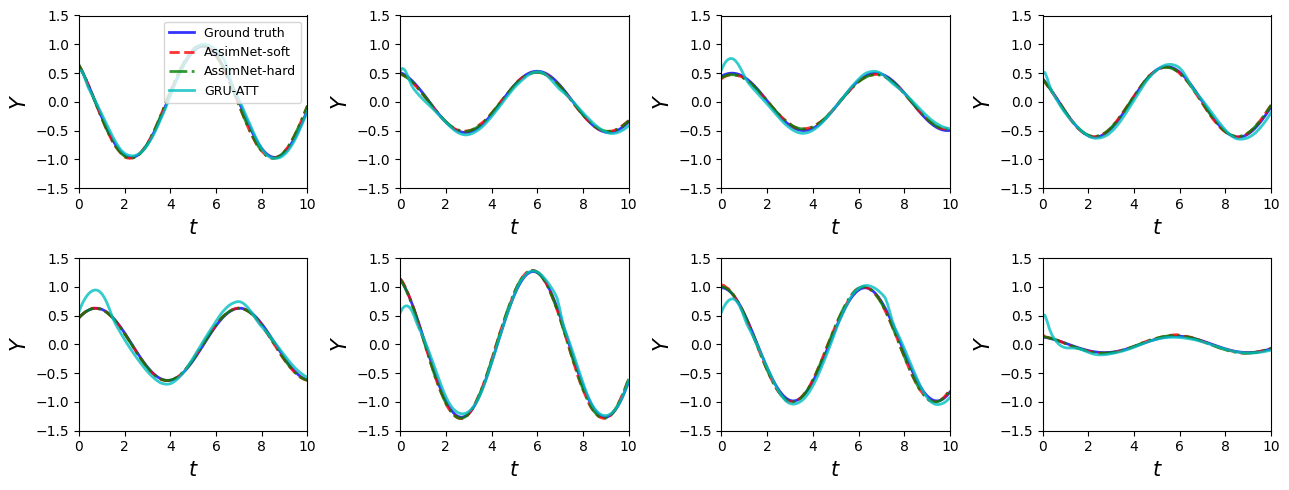

In [ ]:
latent_pred = AssimNet_encoder.predict([org_features_test])
simu_in_pred = vae_decoder_model.predict([latent_pred[0]])
y_pred = proxy.predict(simu_in_pred)

y_predGRUATT = GRUATTmodel.predict(org_features_test)

fig, axs = plt.subplots(2, 4, figsize=(13, 5))
axs = axs.flatten()  # Flatten the 3x3 array of axes into a 1D array for easy indexing

x = np.linspace(0, 10, 100)  # Define x values for constrained output

for idx, i in enumerate(range(61,69)):
    constrained_out = func2(x, simu_in_pred[i][0], simu_in_pred[i][1], simu_in_pred[i][2])

    axs[idx].plot(t, org_data_test[i], label='Ground truth', linewidth = 2, linestyle = '-', color = 'b', alpha = 0.8)
    axs[idx].plot(t, y_pred[i], label='AssimNet-soft', linewidth = 2, color = 'r',  linestyle = '--',alpha = 0.8)
    axs[idx].plot(t, constrained_out, label='AssimNet-hard', linewidth = 2, linestyle = '-.', color = 'g', alpha = 0.8)
    axs[idx].plot(t, y_predGRUATT[i], label='GRU-ATT', linewidth = 2,  linestyle = '-', color = 'c', alpha = 0.8)

    if idx == 0:
        axs[idx].legend(fontsize=9, loc = 'upper right')
    axs[idx].set_xlabel('$t$',fontsize=15)
    axs[idx].set_ylabel('$Y$',fontsize=15)
    axs[idx].set_ylim(-1.5, 1.5)
    axs[idx].set_xlim(0, 10)
plt.tight_layout()